# Lab 1 · From bits to symbols: BPSK, QPSK and 16-QAM
*Digital Communications in Python · Labs by Taha Nadari*

**In this lab you will**
* Map bits to complex symbols for BPSK, QPSK and 16-QAM
* Understand Gray labelling and why neighbours differ by one bit
* Normalise a constellation to unit average energy
* Decide symbols back to bits with a minimum-distance detector

Run the cells from top to bottom (Shift+Enter). `dcomm.py` must be in the same folder.

## 1. Why symbols?
A digital transmitter never sends bits directly. It groups them, **k bits at a time**, and sends one of $M = 2^k$
possible **symbols**. In baseband, a symbol is a complex number $s = I + jQ$: the in-phase ($I$) and quadrature ($Q$)
amplitudes of the carrier. The set of possible symbols is the **constellation**.

| Scheme | bits per symbol $k$ | $M$ |
|---|---|---|
| BPSK | 1 | 2 |
| QPSK | 2 | 4 |
| 16-QAM | 4 | 16 |

More bits per symbol means a higher data rate in the same bandwidth, at the cost of noise robustness (Lab 2).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import dcomm as dc          # the small helper file that comes with the labs
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.grid': True, 'grid.alpha': .3})

## 2. BPSK by hand
One bit per symbol: bit 0 → $-1$, bit 1 → $+1$.

In [2]:
bits = np.array([0, 1, 1, 0, 1, 0, 0, 1], dtype=np.uint8)
s_bpsk = 2.0 * bits - 1          # 0 -> -1, 1 -> +1
print(s_bpsk)

[-1.  1.  1. -1.  1. -1. -1.  1.]


## 3. Gray labelling
For QPSK and QAM, the *order* in which bit patterns are assigned to points matters. Noise usually pushes a symbol
to a **neighbouring** point, so we want neighbours to differ by **one bit only**. That is the Gray code:
$g(n) = n \oplus (n \gg 1)$.

In [3]:
for n in range(8):
    print(n, format(n, '03b'), '->', format(dc.gray(n), '03b'))

0 000 -> 000
1 001 -> 001
2 010 -> 011
3 011 -> 010
4 100 -> 110
5 101 -> 111
6 110 -> 101
7 111 -> 100


## 4. Building 16-QAM
16-QAM is two 4-PAM signals, one on $I$ and one on $Q$, each with levels $\{-3, -1, 1, 3\}$. The first two bits
choose the $I$ level (Gray-labelled), the last two the $Q$ level.

In [4]:
levels = dc.pam_levels(4)                     # [-3, -1, 1, 3]
level_of_label = np.empty(4)
for idx in range(4):
    level_of_label[dc.gray(idx)] = levels[idx]   # Gray label -> amplitude
c16 = np.array([level_of_label[i >> 2] + 1j * level_of_label[i & 3] for i in range(16)])
print('average energy before normalising:', np.mean(np.abs(c16) ** 2))
c16 /= np.sqrt(np.mean(np.abs(c16) ** 2))
print('after:', np.mean(np.abs(c16) ** 2))

average energy before normalising: 10.000000000000002
after: 1.0


We always normalise to **unit average symbol energy** ($E_s = 1$). This makes schemes comparable: in Lab 2 the
noise level is set relative to the energy per bit $E_b = E_s / k$.

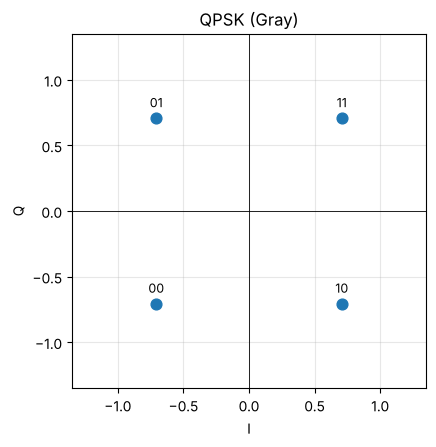

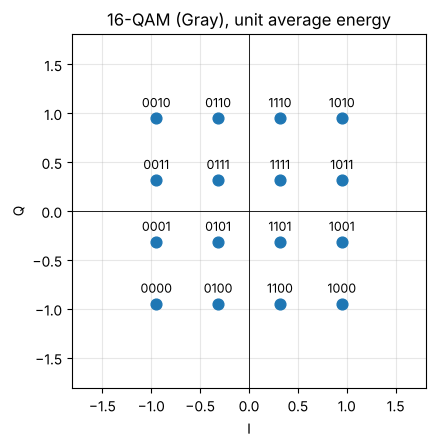

In [5]:
def plot_constellation(c, title):
    k = int(np.log2(len(c)))
    plt.figure(figsize=(4.6, 4.6))
    plt.scatter(c.real, c.imag, s=60, zorder=3)
    for i, p in enumerate(c):
        plt.annotate(format(i, f'0{k}b'), (p.real, p.imag), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)
    plt.axhline(0, color='k', lw=.6); plt.axvline(0, color='k', lw=.6)
    lim = 1.35 * np.max(np.abs(c)); plt.xlim(-lim, lim); plt.ylim(-lim, lim)
    plt.gca().set_aspect('equal'); plt.title(title); plt.xlabel('I'); plt.ylabel('Q'); plt.show()

plot_constellation(dc.constellation('qpsk'), 'QPSK (Gray)')
plot_constellation(c16, '16-QAM (Gray), unit average energy')

Check the labels: any two **horizontally or vertically adjacent** points differ in exactly one bit.

## 5. Modulate and demodulate
The receiver decides, for each received sample, the **closest** constellation point (minimum distance). Without
noise, this gives the bits back exactly.

In [6]:
c = dc.constellation('16qam')
bits = dc.random_bits(4 * 10, seed=1)
symbols = dc.modulate(bits, c)
bits_back = dc.demodulate(symbols, c)
print('symbols:', np.round(symbols[:5], 3))
print('bit errors:', np.sum(bits != bits_back))

symbols: [ 0.316-0.949j  0.316-0.316j -0.316-0.316j  0.316-0.316j  0.949+0.949j]
bit errors: 0


## 6. A first look at noise
Add a little complex Gaussian noise and look at the received cloud. Each cluster is centred on a constellation point;
errors happen when a sample crosses into a neighbour's decision region. Lab 2 makes this quantitative.

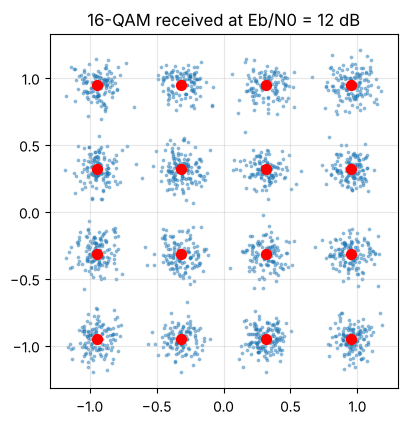

bit errors: 1 out of 8000


In [7]:
bits = dc.random_bits(4 * 2000, seed=2)
rx = dc.awgn(dc.modulate(bits, c), ebn0_db=12, bits_per_symbol=4, seed=3)
plt.figure(figsize=(4.6, 4.6))
plt.scatter(rx.real, rx.imag, s=3, alpha=.4)
plt.scatter(c.real, c.imag, s=50, c='red', zorder=3)
plt.gca().set_aspect('equal'); plt.title('16-QAM received at Eb/N0 = 12 dB'); plt.show()
print('bit errors:', np.sum(dc.demodulate(rx, c) != bits), 'out of', bits.size)

## Exercises: solutions

**E1.** Build 8-PSK by hand: 8 points on the unit circle at angles $2\pi m/8$, with Gray labels. Plot it with `plot_constellation`.

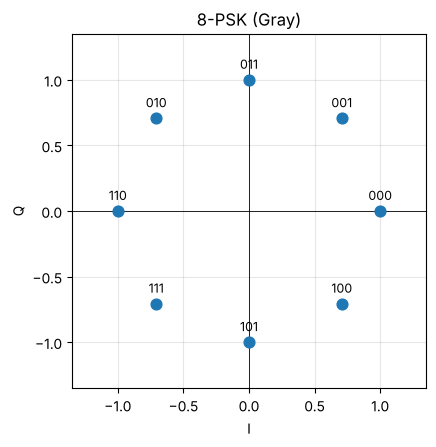

Gray property holds


In [8]:
m = np.arange(8)
c8 = np.empty(8, dtype=complex)
for idx in m:
    c8[dc.gray(idx)] = np.exp(1j * 2 * np.pi * idx / 8)   # point idx (by angle) gets Gray label g(idx)
plot_constellation(c8, '8-PSK (Gray)')
# check: neighbours on the circle differ by one bit
for idx in m:
    a, b = dc.gray(idx), dc.gray((idx + 1) % 8)
    assert bin(a ^ b).count('1') == 1
print('Gray property holds')

**E2.** For 16-QAM normalised to $E_s = 1$, compute the minimum distance $d_{min}$ between two points. Compare with QPSK. What does this say about noise robustness?

In [9]:
def dmin(c):
    d = np.abs(c[:, None] - c[None, :])
    return d[d > 1e-9].min()
for name in ['bpsk', 'qpsk', '16qam', '64qam']:
    print(f'{name:6s} dmin = {dmin(dc.constellation(name)):.3f}')
# 16-QAM: dmin = 2/sqrt(10) = 0.632, vs 1.414 for QPSK: points are 2.2x closer at the same symbol energy,
# so the same noise causes far more errors (about 6-7 dB more Eb/N0 needed, see Lab 2).

bpsk   dmin = 2.000
qpsk   dmin = 1.414
16qam  dmin = 0.632
64qam  dmin = 0.309


**E3.** Replace the Gray labelling of 16-QAM by natural binary labelling (`level_of_label[idx] = levels[idx]`). With the same noisy samples as in section 6, count the bit errors. Explain the difference.

In [10]:
levels = dc.pam_levels(4)
nat = np.array([levels[i >> 2] + 1j * levels[i & 3] for i in range(16)])
nat /= np.sqrt(np.mean(np.abs(nat) ** 2))
bits = dc.random_bits(4 * 20000, seed=5)
for name, cc in [('Gray', dc.constellation('16qam')), ('natural', nat)]:
    rx = dc.awgn(dc.modulate(bits, cc), 8, 4, seed=6)
    print(name, 'bit errors:', np.sum(dc.demodulate(rx, cc) != bits))
# Same symbol errors, but with natural labels a jump to a neighbour can flip 2 bits (e.g. 01 -> 10),
# so the bit error count is higher (roughly 1.3-1.5x here).

Gray bit errors: 788
natural bit errors: 1060
